In [1]:
import os
os.chdir("path")

In [6]:
con = duckdb.connect("ocean.duckdb", read_only=True)

In [7]:
con.sql("SHOW TABLES").df()

,name
0,chl_dineof
1,chl_erd
2,cuti
3,glider
4,kelp
5,pdo
6,photo
7,rain
8,reef
9,sst


In [11]:
import numpy as np
from matplotlib import pyplot

In [10]:
import rasterio

# Open the TIFF file for reading
with rasterio.open('/datasets/bathymetrics_ncei.tif') as src:
    # Read the first band as a NumPy array
    band_1 = src.read(1)

    print('Width:', src.width)
    print('Height:', src.height)
    print('Coordinate Reference System (CRS):', src.crs)
    print('Array shape:', band_1.shape)


Width: 6000
Height: 3018
Coordinate Reference System (CRS): EPSG:4326
Array shape: (3018, 6000)


/var/folders/5h/vhxcqvpj4jb5kdfz5yfnc6f40000gn/T/ipykernel_75841/1869433312.py:6: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  band_1 = src.read(1)


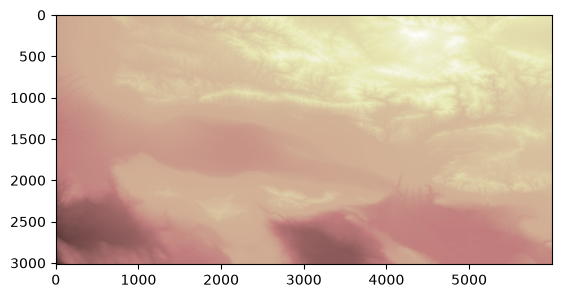

In [16]:
from matplotlib import pyplot
pyplot.imshow(band_1, cmap='pink')

pyplot.show()

---

want to look at the new data from sst and the photo dataset 

In [18]:
sst =  con.execute("SELECT * FROM 'sst'").df()

In [19]:
photo =  con.execute("SELECT * FROM 'photo'").df()

--- 

Seeing how temperature has changed. </br>
Will be last time running it in python will work on aggregating this is SQL that way it isn't running everything in pandas,

In [20]:
sst_average = sst.groupby([ 'ts', 'lat', 'lon']).agg({'sst_c': 'mean'}).reset_index()

In [21]:
sst_average_by_date = sst.groupby([ 'ts']).agg({'sst_c': 'mean'}).reset_index()

<Axes: title={'center': 'Average Sea Surface Temperature Over Time 2008 - 2026'}, xlabel='ts'>

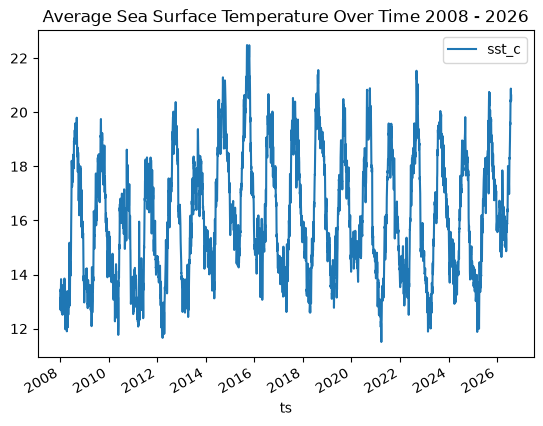

In [22]:
sst_average_by_date.plot(x="ts", y="sst_c", kind="line", title="Average Sea Surface Temperature Over Time 2008 - 2026")

In [27]:
photo_average_by_date = photo.groupby(['ts']).agg({'kdpar': 'mean'}).reset_index()

<Axes: title={'center': 'Average Sea Surface Temperature Over Time 2008 - 2026'}, xlabel='ts'>

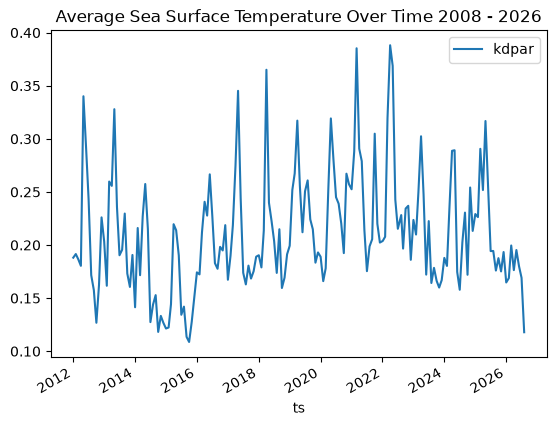

In [28]:
photo_average_by_date.plot(x="ts", y="kdpar", kind="line", title="Average Sea Surface Temperature Over Time 2008 - 2026")